# 02 — Prétraitement et encodage
**Projet Data Mining — Prédiction du départ des employés (Employee Attrition)**

Objectif : transformer le jeu brut en matrices prêtes pour les modèles, **sans fuite de données**.

| Étape | Choix | Justification |
|---|---|---|
| Nettoyage | doublons, plages valides, Yes/No → 1/0 | opérations sans apprentissage : aucun risque de fuite |
| Valeurs manquantes | imputation médiane / mode, **apprise sur le train** | robustesse (l'application peut recevoir des saisies incomplètes) |
| Outliers | écrêtage IQR (k = 3) | ne touche que les valeurs extrêmes, conserve l'information |
| Ordinales (1–5) | conservées en numérique | l'ordre est informatif ; le one-hot le perdrait |
| Nominale (`Department`) | one-hot | pas d'ordre naturel |
| Échelle | Z-score (StandardScaler) | indispensable pour K-NN, SVM, Naïve Bayes gaussien |
| Découpage | 80/20 stratifié, `random_state=42` | conserve ~9 % de départs dans chaque jeu |

In [2]:
import sys, warnings
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing import *
sns.set_theme(style="whitegrid")

## 1. Chargement et vue d'ensemble

In [3]:
raw = load_raw(ROOT / "data" / "raw" / "Employee_Attrition_DataSet.csv")
print(raw.shape)
raw.head()

(10000, 14)


,EmployeeID,Age,Department,JobLevel,YearsAtCompany,MonthlyIncome,JobSatisfaction,WorkLifeBalance,OverTime,DistanceFromHome,PromotionLast5Years,PerformanceRating,TrainingHoursLastYear,Attrition
0,EMP0000,42,Sales,3,9,9866,4,1,No,24.5,Yes,4,19,No
1,EMP0001,36,Sales,3,7,8958,3,3,No,10.0,No,2,13,No
2,EMP0002,44,Sales,4,16,11716,4,3,No,4.0,No,4,13,No
3,EMP0003,53,Finance,4,30,17061,5,3,No,7.1,No,3,20,No
4,EMP0004,35,HR,2,4,5738,2,3,No,8.4,No,2,15,No


In [4]:
raw.dtypes

EmployeeID                   str
Age                        int64
Department                   str
JobLevel                   int64
YearsAtCompany             int64
MonthlyIncome              int64
JobSatisfaction            int64
WorkLifeBalance            int64
OverTime                     str
DistanceFromHome         float64
PromotionLast5Years          str
PerformanceRating          int64
TrainingHoursLastYear      int64
Attrition                    str
dtype: object

## 2. Contrôles qualité (avant tout traitement)

In [5]:
quality = pd.DataFrame({
    "manquants": raw.isna().sum(),
    "% manquants": (raw.isna().mean() * 100).round(2),
    "valeurs uniques": raw.nunique(),
})
print("Lignes dupliquées :", raw.duplicated().sum(), "| ID dupliqués :", raw[ID_COL].duplicated().sum())
quality

Lignes dupliquées : 0 | ID dupliqués : 0


,manquants,% manquants,valeurs uniques
EmployeeID,0,0.0,10000
Age,0,0.0,39
Department,0,0.0,7
JobLevel,0,0.0,5
YearsAtCompany,0,0.0,36
MonthlyIncome,0,0.0,6784
JobSatisfaction,0,0.0,5
WorkLifeBalance,0,0.0,4
OverTime,0,0.0,2
DistanceFromHome,0,0.0,381


## 3. Nettoyage (sans apprentissage)
`clean_data` normalise les textes, supprime les doublons, met à `NaN` toute valeur hors plage plausible et encode Yes/No → 1/0.

In [6]:
df, report = clean_data(raw)
{k: v for k, v in report.items()}

{'rows_raw': 10000,
 'columns_raw': 14,
 'duplicate_rows_removed': 0,
 'duplicate_ids_removed': 0,
 'out_of_range_to_nan': {},
 'rows_without_target_removed': 0,
 'missing_after_cleaning': {},
 'rows_clean': 10000}

**Constat** : le jeu est déjà propre (0 doublon, 0 valeur manquante, 0 valeur hors plage). La fonction reste utile : elle protège le pipeline si on change de données et sert l'application de prédiction.

## 4. Valeurs aberrantes
Détection par la règle de Tukey : une valeur est atypique si elle sort de `[Q1 − k·IQR ; Q3 + k·IQR]`. `k = 1,5` détecte les atypiques, `k = 3` les extrêmes.

In [7]:
iqr_outlier_report(df)

,Q1,Q3,outliers_k=1.5,outliers_k=3.0
variable,,,,
Age,31.0,44.0,0,0
YearsAtCompany,2.0,12.0,142,0
MonthlyIncome,6043.5,11484.0,12,0
DistanceFromHome,4.7,13.4,306,24
TrainingHoursLastYear,12.0,18.0,15,0


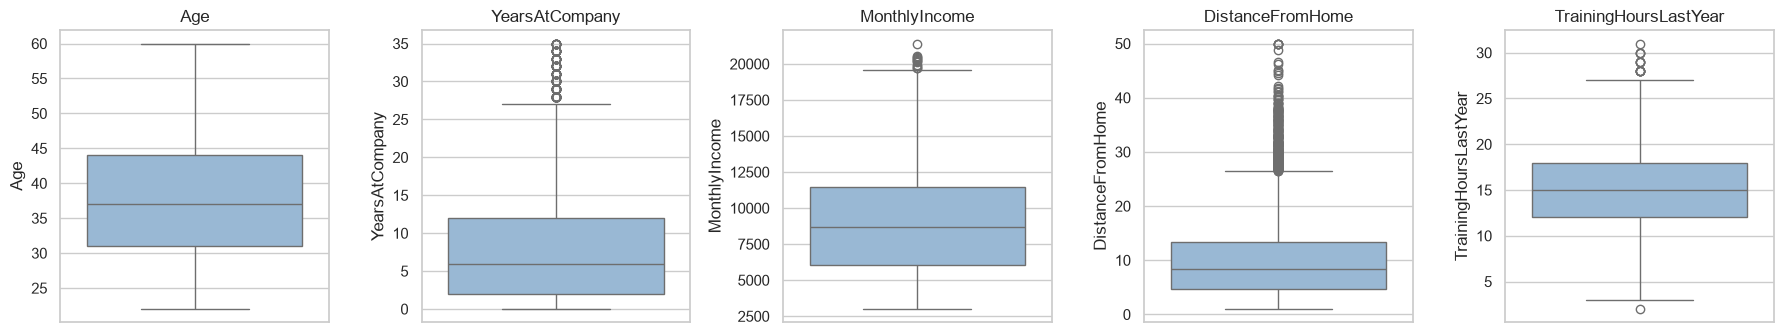

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, NUMERIC_COLS):
    sns.boxplot(y=df[col], ax=ax, color="#8fb8de"); ax.set_title(col)
plt.tight_layout(); plt.show()

**Décision** : on **ne supprime aucune ligne**. Les valeurs atypiques (ex. 35 ans d'ancienneté, revenu de 21 410) sont plausibles. On applique seulement un écrêtage à k = 3, qui ne touche que `DistanceFromHome` (24 valeurs). Les bornes sont apprises sur le train.

## 5. Déséquilibre de la cible

Attrition
Reste (0)    9097
Part (1)      903
Name: count, dtype: int64 
Taux de départ : 9.03%
Accuracy d'un classifieur Zero-R : 90.97%


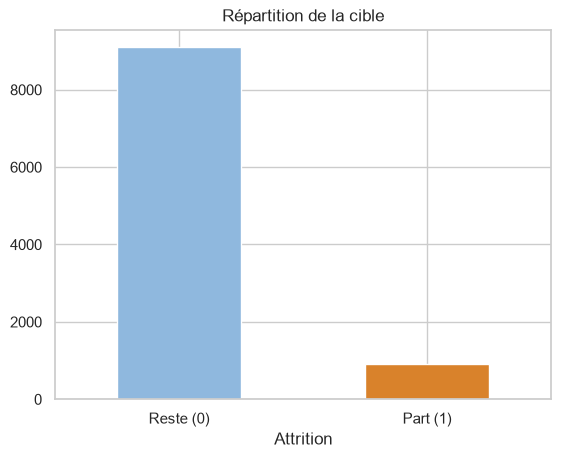

In [9]:
counts = df[TARGET].value_counts().rename({0: "Reste (0)", 1: "Part (1)"})
print(counts, "\nTaux de départ :", f"{df[TARGET].mean():.2%}")
print(f"Accuracy d'un classifieur Zero-R : {1 - df[TARGET].mean():.2%}")
counts.plot.bar(color=["#8fb8de", "#d9822b"], rot=0, title="Répartition de la cible"); plt.show()

Un modèle qui prédit toujours « reste » obtient ~91 % d'accuracy. **L'accuracy est donc une mauvaise métrique ici** : on optimisera F1 / average precision et on lira le rappel de la classe « part ».

## 6. Découpage train / test
Le découpage se fait **avant** tout apprentissage de statistiques (médianes, bornes IQR, moyennes, écarts-types).

In [10]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print(f"Taux de départ  train={y_train.mean():.2%}  test={y_test.mean():.2%}")

Train : (8000, 12) | Test : (2000, 12)
Taux de départ  train=9.03%  test=9.05%


## 7. Encodage et standardisation (ajustés sur le train uniquement)

In [11]:
pre = build_preprocessor()
Xtr = pre.fit_transform(X_train)   # fit sur le train
Xte = pre.transform(X_test)        # transform seul sur le test
print(Xtr.shape, Xte.shape)
Xtr.head()

(8000, 18) (2000, 18)


,Age,YearsAtCompany,MonthlyIncome,DistanceFromHome,TrainingHoursLastYear,JobLevel,JobSatisfaction,WorkLifeBalance,PerformanceRating,OverTime,PromotionLast5Years,Department_Engineering,Department_Finance,Department_HR,Department_IT,Department_Marketing,Department_Operations,Department_Sales
6116,0.882720,-0.806503,-0.924540,1.794050,0.518438,-0.328341,0.600657,1.397107,0.536101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4568,1.521052,0.175476,0.461893,0.968649,-1.023864,0.549869,-0.340812,1.397107,-0.823699,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3998,1.733829,1.017173,1.949298,-0.131885,-1.795015,1.428079,1.542125,-0.848143,0.536101,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
682,-0.606721,0.175476,0.812577,-1.145535,-0.766813,0.549869,-0.340812,-0.848143,-0.823699,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3244,-0.181167,0.315759,0.986489,-0.740075,-1.280914,0.549869,-0.340812,1.397107,1.895900,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
check = pd.DataFrame({"moyenne train": Xtr[NUMERIC_COLS].mean(), "écart-type train": Xtr[NUMERIC_COLS].std(),
                      "moyenne test": Xte[NUMERIC_COLS].mean()}).round(3)
check

,moyenne train,écart-type train,moyenne test
Age,0.0,1.0,-0.005
YearsAtCompany,-0.0,1.0,0.028
MonthlyIncome,-0.0,1.0,0.028
DistanceFromHome,-0.0,1.0,-0.009
TrainingHoursLastYear,0.0,1.0,0.013


La moyenne vaut 0 sur le train (par construction) et **seulement environ** 0 sur le test : c'est le signe attendu qu'aucune information du test n'a servi au calibrage.

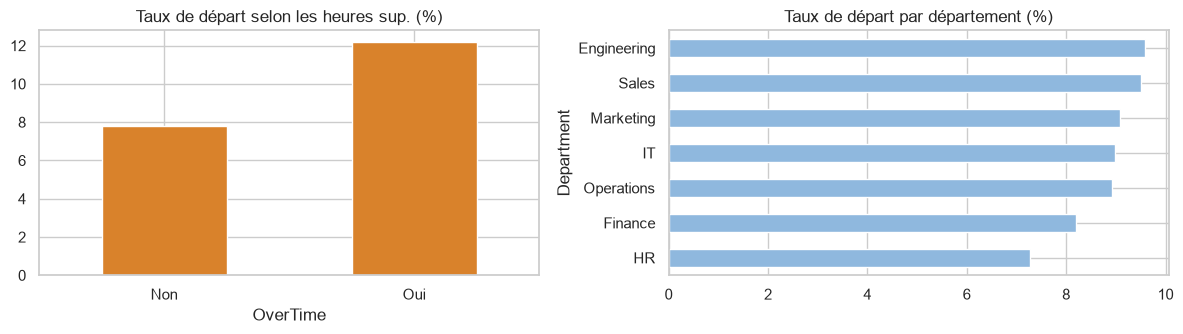

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.groupby("OverTime")[TARGET].mean().rename({0: "Non", 1: "Oui"}).mul(100).plot.bar(ax=ax[0], rot=0, color="#d9822b")
ax[0].set_title("Taux de départ selon les heures sup. (%)")
df.groupby("Department")[TARGET].mean().mul(100).sort_values().plot.barh(ax=ax[1], color="#8fb8de")
ax[1].set_title("Taux de départ par département (%)")
plt.tight_layout(); plt.show()

## 8. Sauvegarde
Exécutée par `scripts/run_preprocessing.py` (même code, reproductible) : fichiers `X_*`, `X_*_raw`, `y_*` dans `data/processed/`, transformateur dans `models/preprocessor.joblib`, bilan dans `results/preprocessing_report.json`.

In [14]:
import joblib
PROCESSED = ROOT / "data" / "processed"
Xtr.to_csv(PROCESSED / "X_train.csv", index=False);  Xte.to_csv(PROCESSED / "X_test.csv", index=False)
X_train.to_csv(PROCESSED / "X_train_raw.csv", index=False);  X_test.to_csv(PROCESSED / "X_test_raw.csv", index=False)
y_train.to_csv(PROCESSED / "y_train.csv", index=False);  y_test.to_csv(PROCESSED / "y_test.csv", index=False)
joblib.dump(pre, ROOT / "models" / "preprocessor.joblib")
print("Sauvegarde terminée :", sorted(p.name for p in PROCESSED.glob("*.csv")))

Sauvegarde terminée : ['X_test.csv', 'X_test_raw.csv', 'X_train.csv', 'X_train_raw.csv', 'attrition_report.csv', 'y_test.csv', 'y_train.csv']


## Synthèse
- Jeu brut : 10 000 lignes × 14 colonnes → 18 variables après encodage (5 continues, 4 ordinales, 2 binaires, 7 indicatrices `Department`).
- Aucune ligne supprimée ; écrêtage IQR (k = 3) ; imputation prévue mais inactive sur ces données.
- Cible déséquilibrée (~9 % de départs) → métriques adaptées et pondération des classes à l'étape suivante.